In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Initialize Aer simulator backend and shot count
simulator = AerSimulator()
SHOTS = 100

print("Libraries imported successfully!")

Libraries imported successfully!


# Challenge 4: Quantum Correlation Switch
**Name:** POLAMARASETTY JAGADEESH 
**Event:** Qiskit Fall Fest 2026 - Vishnu Institute of Technology  

## Part 1: Theoretical Predictions ("Think Before You Run")

### Part A: Correlated Outcomes (|00⟩ and |11⟩)
- **Circuit Design:** Apply Hadamard ($H$) on $q_0$, then $CNOT$ with control $q_0$ and target $q_1$ (2 gates $\le$ 4 gates limit).
- **State Transformation:**
  $$\vert{}00\rangle \xrightarrow{H_0} \frac{1}{\sqrt{2}}(\vert{}00\rangle + \vert{}10\rangle) \xrightarrow{CNOT_{0,1}} \vert{}\Phi^+\rangle = \frac{1}{\sqrt{2}}(\vert{}00\rangle + \vert{}11\rangle)$$
- **Prediction:** The outcomes will be strongly correlated (identical bits). `00` and `11` dominate with ~50% probability each.
- **Expected Counts (100 shots):** `{'00': ~50, '11': ~50}`. `01` and `10` will have 0 counts.

### Part B: Opposite Outcomes (|01⟩ and |10⟩)
- **Circuit Design:** Start with the entangled Bell pair and apply an $X$ gate to $q_0$ before measurement ($H_0 \rightarrow CNOT_{0,1} \rightarrow X_0$, 3 gates $\le$ 4 gates limit).
- **State Transformation:**
  $$\frac{1}{\sqrt{2}}(\vert{}00\rangle + \vert{}11\rangle) \xrightarrow{X_0} \vert{}\Psi^+\rangle = \frac{1}{\sqrt{2}}(\vert{}10\rangle + \vert{}01\rangle)$$
- **Prediction:** The outcomes switch to being completely opposite (anti-correlated). `01` and `10` dominate with ~50% probability each.
- **Expected Counts (100 shots):** `{'01': ~50, '10': ~50}`. `00` and `11` will have 0 counts.

### Key Questions:
- **Will all four possible outcomes appear?** No, in an ideal simulator, only two basis states appear per circuit because probability amplitudes for the other two states evaluate to zero.
- **Why are some outcomes much more frequent than others?** Quantum entanglement creates constructive interference for target states and complete destructive cancellation for non-target states.

Circuit A (Correlated Outcomes):


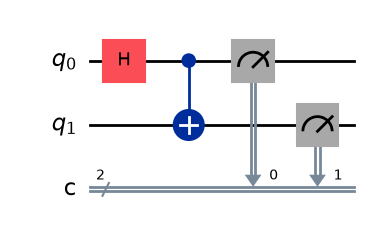

Results for Circuit A (100 shots): {'00': 51, '11': 49}


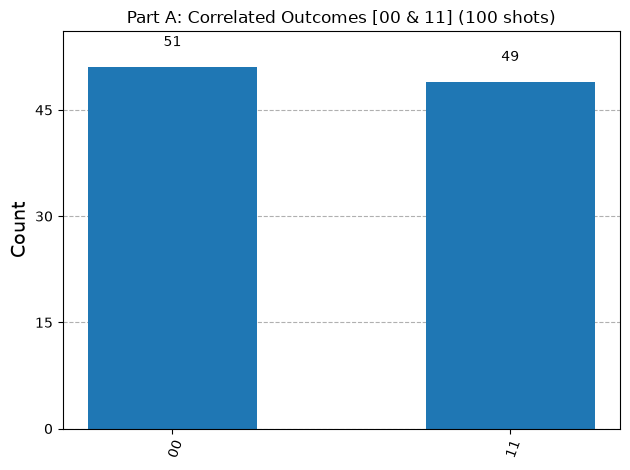

In [2]:
# 1. Create a 2-qubit, 2-classical-bit circuit
qc_a = QuantumCircuit(2, 2)

# 2. Build Bell state: H on q0, CNOT(0, 1)
qc_a.h(0)
qc_a.cx(0, 1)

# 3. Add measurements
qc_a.measure([0, 1], [0, 1])

# 4. Draw circuit
print("Circuit A (Correlated Outcomes):")
display(qc_a.draw('mpl'))

# 5. Run simulation for 100 shots
job_a = simulator.run(qc_a, shots=SHOTS)
counts_a = job_a.result().get_counts()
print(f"Results for Circuit A (100 shots): {counts_a}")

# 6. Plot histogram
display(plot_histogram(counts_a, title="Part A: Correlated Outcomes [00 & 11] (100 shots)"))

Circuit B (Opposite Outcomes):


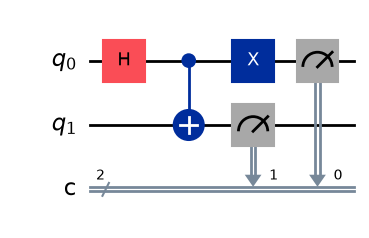

Results for Circuit B (100 shots): {'01': 42, '10': 58}


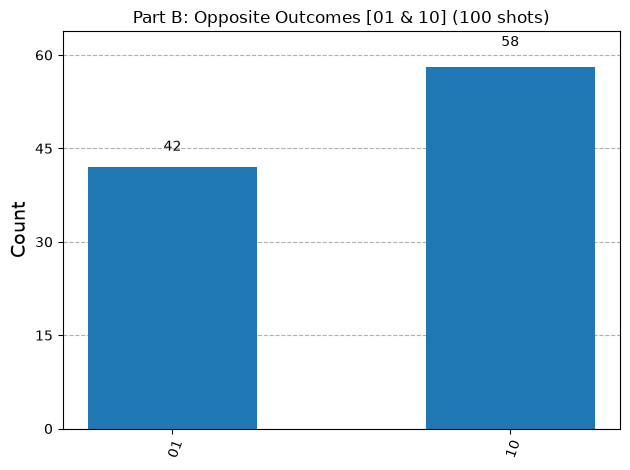

In [3]:
# 1. Create a 2-qubit, 2-classical-bit circuit
qc_b = QuantumCircuit(2, 2)

# 2. Build entangled state and switch correlation using an X gate
qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(0)  # Added X gate on qubit 0 to switch correlation

# 3. Add measurements
qc_b.measure([0, 1], [0, 1])

# 4. Draw circuit
print("Circuit B (Opposite Outcomes):")
display(qc_b.draw('mpl'))

# 5. Run simulation for 100 shots
job_b = simulator.run(qc_b, shots=SHOTS)
counts_b = job_b.result().get_counts()
print(f"Results for Circuit B (100 shots): {counts_b}")

# 6. Plot histogram
display(plot_histogram(counts_b, title="Part B: Opposite Outcomes [01 & 10] (100 shots)"))

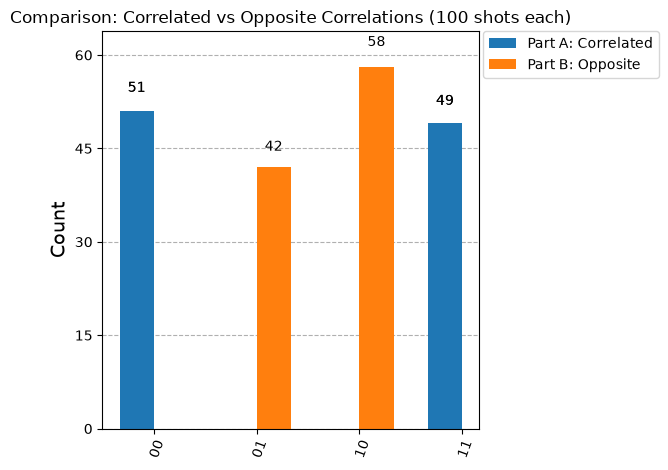

In [4]:
# Combined histogram comparison
display(plot_histogram([counts_a, counts_b],
                       legend=['Part A: Correlated', 'Part B: Opposite'],
                       title="Comparison: Correlated vs Opposite Correlations (100 shots each)"))

## Part C: Comparison & Analysis

| Circuit | Gate Sequence | State Prepared | Dominant Outcomes | Typical Results (100 shots) | Correlation Behavior |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Part A** | $H_0 \rightarrow CNOT_{0,1}$ | $\vert{}\Phi^+\rangle = \frac{1}{\sqrt{2}}(\vert{}00\rangle + \vert{}11\rangle)$ | `00` and `11` | e.g., `{'00': 48, '11': 52}` | **Correlated** (Identical measurement outcomes) |
| **Part B** | $H_0 \rightarrow CNOT_{0,1} \rightarrow X_0$ | $\vert{}\Psi^+\rangle = \frac{1}{\sqrt{2}}(\vert{}01\rangle + \vert{}10\rangle)$ | `01` and `10` | e.g., `{'01': 53, '10': 47}` | **Opposite** (Anti-correlated measurement outcomes) |

### Detailed Answers to Analysis Questions:

1. **Which outcomes are dominant in Part A?**
   - Outcomes `00` and `11` dominate exclusively (~50% each)[cite: 4].
2. **Which outcomes are dominant in Part B?**
   - Outcomes `01` and `10` dominate exclusively (~50% each)[cite: 4].
3. **What changed between the two circuits?**
   - An $X$ (NOT) gate was inserted on qubit $q_0$ after the entangling $CNOT$ operation[cite: 4].
4. **Why did the measurement relationship change?**
   - The $CNOT$ gate pairs the state of $q_1$ directly with $q_0$, causing their measurement states to be identical ($\vert{}00\rangle$ or $\vert{}11\rangle$)[cite: 4].
   - Introducing the $X$ gate applies a deterministic bit-flip to the target qubit: $\vert{}00\rangle \rightarrow \vert{}10\rangle$ and $\vert{}11\rangle \rightarrow \vert{}01\rangle$.
   - This unitary operation flips the relative phase/parity of the measurement outcomes, switching the entanglement from identical correlation to complete anti-correlation without collapsing the quantum superposition[cite: 4].